<a href="https://colab.research.google.com/github/Muhammadjon1211/computer_vision/blob/master/menu_detectoor_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
print("Menu Detector!")

Menu Detector!


In [2]:
# ----------------
# Import Libraries
# ----------------

from google.colab import drive
import torchvision.transforms as transform
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms

from PIL import Image, UnidentifiedImageError
from torch.utils.data import Dataset, DataLoader
import os
import numpy as np

from torchvision.models import mobilenet_v2

In [3]:
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Define dataset path

DATASET_PATH = '/content/drive/MyDrive/food101_dataset'
print("Dataset_path:",DATASET_PATH)

CUSTOM_CLASS_MAPPING = {
    "hamburger": "hamburger",
    "hot_dog": "hot-dog",
    "cheescake": "dessert",      # label grouping | class consolation
    "chocolate_cake": "dessert", # label grouping | class consolation
    "kebab": "kebab",
    "pilaf": "pilaf"
}

CLASSES = ['hamburger', 'hot-dog', 'dessert', 'kebab', 'pilaf']
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)

print(NUM_CLASSES)
print(CLASS_TO_IDX)

transform = transforms.Compose([ # saves the order of workflow
    transforms.Resize((224, 224)), # same size for images
    transforms.ToTensor(), # images to tensor(numbers)
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

Dataset_path: /content/drive/MyDrive/food101_dataset
5
{'hamburger': 0, 'hot-dog': 1, 'dessert': 2, 'kebab': 3, 'pilaf': 4}


In [5]:
# ---------------------
# Custom dataset class
# ---------------------

class FoodDataset(Dataset):
  def __init__(self, images, labels, transform=None):
    self.images = images
    self.transform = transform
    self.labels = labels

  def __len__(self):
    print("images_length:", len(self.images))
    return len(self.images)

  def __getitem__(self, idx):
    img_path = self.images[idx]
    print("image_path:", img_path)
    label = self.labels[idx]
    print("label:", label)

    try:
      image = Image.open(img_path).convert('RGB')
    except (UnidentifiedImageError, OSError):
      print(f"Skipping broken image: {img_path}")
      return self.__getitem__((idx+1) % len(self.images))
    if self.transform:
      image = self.transform(image)
    return image, label

In [6]:
# ---------------------
# Gather and split data
# ---------------------

all_images = []

for original_class, mapped_class in CUSTOM_CLASS_MAPPING.items():
  class_path = os.path.join(DATASET_PATH, original_class)
  print("class_path:", class_path)

  if not os.path.exists(class_path):
    print(f"Warnings: {class_path} not found")
    continue
  for img in os.listdir(class_path):
    if img.endswith(('.jpg', 'jpeg', 'png')):
      full_path = os.path.join(class_path, img)
      all_images.append((full_path, CLASS_TO_IDX[mapped_class]))

np.random.shuffle(all_images)
split = int(0.8 * len(all_images))
train_data = all_images[:split]
test_data = all_images[split:]

train_images, train_labels = zip(*train_data)
val_images, val_labels = zip(*test_data)

print("all_images:", all_images)

dataset = FoodDataset(train_images, train_labels)
print(len(dataset))
img, lbl = dataset[0]

class_path: /content/drive/MyDrive/food101_dataset/hamburger
class_path: /content/drive/MyDrive/food101_dataset/hot_dog
class_path: /content/drive/MyDrive/food101_dataset/cheescake
Warnings: /content/drive/MyDrive/food101_dataset/cheescake not found
class_path: /content/drive/MyDrive/food101_dataset/chocolate_cake
class_path: /content/drive/MyDrive/food101_dataset/kebab
class_path: /content/drive/MyDrive/food101_dataset/pilaf
all_images: [('/content/drive/MyDrive/food101_dataset/hot_dog/3690427.jpg', 1), ('/content/drive/MyDrive/food101_dataset/kebab/Image_59.jpg', 3), ('/content/drive/MyDrive/food101_dataset/chocolate_cake/3327904.jpg', 2), ('/content/drive/MyDrive/food101_dataset/chocolate_cake/3110671.jpg', 2), ('/content/drive/MyDrive/food101_dataset/chocolate_cake/1119923.jpg', 2), ('/content/drive/MyDrive/food101_dataset/hamburger/868903.jpg', 0), ('/content/drive/MyDrive/food101_dataset/hamburger/1230241.jpg', 0), ('/content/drive/MyDrive/food101_dataset/hot_dog/485835.jpg', 1),

In [7]:
train_dataset = FoodDataset(train_images, train_labels, transform=transform)
val_dataset = FoodDataset(val_images, val_labels, transform=transform)

In [8]:
train_loader = DataLoader(train_dataset, batch_size=32, num_workers=2, shuffle=True) # thread | parallel laoding for speed
val_loader = DataLoader(val_dataset, batch_size=32, num_workers=2, shuffle=False)

images_length: 2471
images_length: 2471


In [9]:
# pretrained model
model = mobilenet_v2(weights="IMAGENET1K_V1") # pretrained model | lightweight | CNN | 1000 class | million
model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES) # fine-tuning | backbone | model layer freeze

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 131MB/s]


In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device", device)
model = model.to(device)

device cuda


In [11]:
criterion = nn.CrossEntropyLoss() # Loss Function
optimizer = optim.Adam(model.parameters(), lr=0.001) # update parameters(weights) learning rate
torch.backends.cudnn.benchmark = True # Benchmark setting | Trick best algorithm for your gpu | perfomance speed

In [12]:
# ---------------------
# Training Loop
# ---------------------

NUM_EPOCHS = 10
best_accuracy = 0.0

for epoch in range(NUM_EPOCHS):
    model.train()  # Train mode
    running_loss = 0.0

    for images, labels in train_loader:  # Forward and Backward (Backpropagation)
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()  # Zero the gradient
        outputs = model(images)  # Forward pass
        loss = criterion(outputs, labels)  # Calculate loss

        loss.backward()
        optimizer.step()  # Adam optimizer

        running_loss += loss.item()  # Track loss

    # Validation
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_acc = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
        f"Loss: {running_loss/len(train_loader):.4f}, "
        f"Val Accuracy: {val_acc:.2f}%"
    )

    if val_acc > best_accuracy:
        best_accuracy = val_acc
        torch.save(model.state_dict(), "/content/menu_detector.pth")
        print("Saved new best model!")

Streaming output truncated to the last 5000 lines.
image_path:image_path:  /content/drive/MyDrive/food101_dataset/hot_dog/2207409.jpg/content/drive/MyDrive/food101_dataset/chocolate_cake/3824495.jpg

label:label:  12

image_path: /content/drive/MyDrive/food101_dataset/hamburger/2771605.jpg
label: 0image_path:
 /content/drive/MyDrive/food101_dataset/chocolate_cake/1026971.jpg
label:image_path: 2
 /content/drive/MyDrive/food101_dataset/hot_dog/1395444.jpg
label: 1image_path: 
/content/drive/MyDrive/food101_dataset/hot_dog/2553535.jpg
label: image_path:1 
/content/drive/MyDrive/food101_dataset/chocolate_cake/449197.jpg
label: image_path:2 
/content/drive/MyDrive/food101_dataset/hamburger/3818286.jpg
label: 0
image_path: /content/drive/MyDrive/food101_dataset/chocolate_cake/3603070.jpgimage_path:
label: /content/drive/MyDrive/food101_dataset/chocolate_cake/3501086.jpg
 label:2 
2
image_path: image_path:/content/drive/MyDrive/food101_dataset/hot_dog/1166929.jpg /content/drive/MyDrive/food10

device: cuda
Upload one or more images of hamburger or hot dog:


Saving images (1).jpg to images (1) (1).jpg


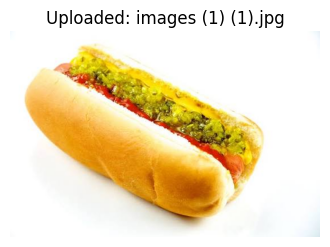

Prediction:
  hot_dog: 95.21%
  hamburger: 3.62%
  dessert: 0.91%
  kebab: 0.20%


In [3]:
# ----------------------------------------
# Required Imports
# ----------------------------------------
import torch
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2
from PIL import Image
from google.colab import files
import io
import matplotlib.pyplot as plt

# ----------------------------------------
# Define Semantic Classes
# ----------------------------------------
CLASSES = ['hamburger', 'hot_dog', 'dessert', 'kebab', 'pilaf']  # Must match training order
NUM_CLASSES = len(CLASSES)
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}

# ----------------------------------------
# Transform for Uploaded Images (no augmentations!)
# ----------------------------------------
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# ----------------------------------------
# Load Model
# ----------------------------------------
model = mobilenet_v2(weights=None)
model.classifier[1] = torch.nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
model.load_state_dict(torch.load('/content/menu_detector.pth', map_location='cpu'))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)
model = model.to(device)
model.eval()

# ----------------------------------------
# Upload & Predict
# ----------------------------------------
print("Upload one or more images of hamburger or hot dog:")
uploaded = files.upload()

for image_name in uploaded.keys():
    image = Image.open(io.BytesIO(uploaded[image_name])).convert('RGB')

    # Display image[cite: 2]
    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.axis('off')
    plt.title(f'Uploaded: {image_name}')
    plt.show()

    # Predict
    image_tensor = transform(image).unsqueeze(0).to(device)
    with torch.no_grad():
        output = model(image_tensor)
        probs = torch.softmax(output, dim=1)[0]
        topk = torch.topk(probs, 4)

    print("Prediction:")
    for i in range(topk.indices.size(0)):
        label = CLASSES[topk.indices[i]]
        confidence = topk.values[i].item() * 100
        print(f"  {label}: {confidence:.2f}%")